## Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import tifffile as tiff
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

from torch.amp import GradScaler
from torch.amp import autocast

import segmentation_models_pytorch as smp

from torchvision.transforms import Compose, ToTensor
import albumentations as A

from PotsdamDataset import PotsdamDataset
from plot_functions import display_image_tensor, display_prediction, plot_train_val_losses, plot_train_val_metrics

#from training_loop import DiceFocalLoss, output_to_label, training_loop, train_epoch, validate, confusion_matrix_6x6, test_score
from training_loop_autocast import DiceFocalLoss, output_to_label, training_loop, train_epoch, validate, confusion_matrix_6x6, test_score

In [2]:
print("segmentation_models_pytorch version:", smp.__version__)

# FocalLoss in version 0.5.0 strictly expects raw logits

segmentation_models_pytorch version: 0.5.0


In [3]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA Version:", torch.version.cuda)

PyTorch Version: 2.3.1+cu118
CUDA Available: True
CUDA Version: 11.8


In [4]:
TRAIN_DIR = Path("train_patches/images")
VAL_DIR = Path("val_patches/images")

image_files = sorted(TRAIN_DIR.glob("*.tif"))
val_files = sorted(VAL_DIR.glob("*.tif"))

print(len(image_files))
print(len(val_files))


1883
605


## Build vanilla U-Net model for semantic segmentation 

PyTorch expects images in (channels × height × width) format, or (C, H, W).
- Single Image: (C, H, W) — for example, a 3-channel RGB image is ``(3, H, W)``.
- Batch of Images: ``(B, C, H, W)`` — where B is the batch size

- Unlike libraries like Matplotlib, OpenCV, or NumPy/PIL arrays which typically use (H, W, C) (channels-last), PyTorch standardizes on "channels-first" (C, H, W) for its convolutional layers and transforms.

## Model architecture

- Design follows the original U-Net architecture with the exception that the downsampling are done in three stages instead of four, and the upsampling is done in three stages as well.
    - This choice was made in order to have less parameters to train

- Padding of 1 is applied to all 3x3 conv layers in order to keep image dimensions intact

- Skip-connections
    - Endoced data is concatenated to up-sampled data (both having same dimensions)  


In [5]:
class Vanilla_UNet(nn.Module):

    def __init__(self, img_dim:int, n_class:int, in_channels:int=3):

        super().__init__()
        
        self.n_class = n_class
        self.in_channels = in_channels
        self.out_channels = n_class
        self.img_dim = img_dim

        if self.img_dim  < 256:
            raise ValueError("Image dimension must be at least 256x256 for this U-Net implementation.")
        if self.img_dim % 256 != 0:
            raise ValueError("Image dimension must be a multiple of 256 for this U-Net implementation.")


        # Define the U-Net model using torch.nn


        # ---- MAXPOOLING ----
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)



        # ---- ENCODER ----
        
        # output used in skip connection
        self.encode_1 = nn.Sequential(
            nn.Conv2d(self.in_channels, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output used in skip connection
        self.encode_2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output used in skip connection
        self.encode_3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- BRIDGE ---- 
        # to connect encoder and decoder
        self.bridge = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- UP-SAMPLING ----
        # Upconvolution layers to upsample the feature maps back to the original image size
        self.upconv_3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)   # increase the spatial dimensions (64 --> 128)
        self.upconv_2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)   # increase the spatial dimensions (128 --> 256)
        self.upconv_1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)    # increase the spatial dimensions (256 --> 512)



        # ---- DECODER -----
        self.decode_3 = nn.Sequential(
            nn.Conv2d(512, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_2 = nn.Sequential(
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_1 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- FINAL CONVOLUTION LAYER ----
        # Final layer to map to the desired number of classes
        self.final_conv = nn.Conv2d(64, self.out_channels, kernel_size=1)  




    def forward(self, x):

        # --- Encoder ---
        encoded_1 = self.encode_1(x)

        x = self.maxpool(encoded_1)

        encoded_2 = self.encode_2(x)

        x = self.maxpool(encoded_2)

        encoded_3 = self.encode_3(x)

        x = self.maxpool(encoded_3)



        # --- Bridge ---
        x = self.bridge(x)



        # --- Decoder ---
        
        # increase the spatial dimensions (64 --> 128)
        # decrease the number of channels (512 --> 256)
        x = self.upconv_3(x) 
        # Concatenate along the channel dimension 
        # dim=1 since PyTorch uses (N,C,H,W) format, where N is batch size, C is channels, H is height, W is width
        # number of channels after concatenation will be 256 (from upconv_3) + 256 (from encoded_3) = 512
        x = torch.cat((encoded_3, x), dim=1)

        x = self.decode_3(x)



        # increase the spatial dimensions (128 --> 256)
        # decrease the number of channels (256 --> 128)
        x = self.upconv_2(x)
        # number of channels after concatenation will be 128 (from upconv_2) + 128 (from encoded_2) = 256
        x = torch.cat((encoded_2, x), dim=1)
        
        x = self.decode_2(x)



        # increase the spatial dimensions (256 --> 512)
        # decrease the number of channels (128 --> 64)
        x = self.upconv_1(x)

        # number of channels after concatenation will be 64 (from upconv_1) + 64 (from encoded_1) = 128
        x = torch.cat((encoded_1, x), dim=1)
        
        x = self.decode_1(x)



        # --- Final layer --- 
        # to map to the desired number of classes
        x = self.final_conv(x)

        return x


# Initialize datasets and dataloaders

In [6]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5), ])


train_dataset = PotsdamDataset(root="./train_patches", transform=train_transform)
val_dataset = PotsdamDataset(root="./val_patches", transform=None)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

In [7]:
print(f"The example dataset is: {train_dataset}")
print(f"The example dataset type is: {type(train_dataset)}")
number_of_samples = len(train_dataset)
print(f"The number of samples is: {number_of_samples}")

img, label = train_dataset[200]

print(type(img), type(label))
print(img.dtype, label.dtype)
print(img.shape, label.shape)


The example dataset is: <PotsdamDataset.PotsdamDataset object at 0x74a6139b6810>
The example dataset type is: <class 'PotsdamDataset.PotsdamDataset'>
The number of samples is: 1883
<class 'torch.Tensor'> <class 'torch.Tensor'>
torch.float32 torch.int64
torch.Size([3, 512, 512]) torch.Size([512, 512])


Image shape: torch.Size([3, 512, 512])  
Label shape: torch.Size([512, 512])


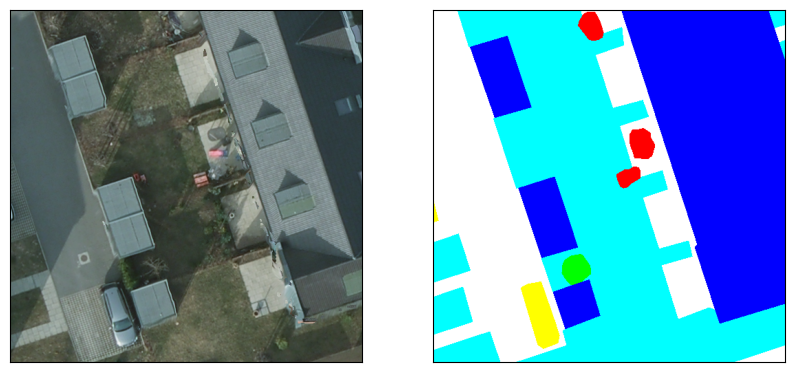

In [8]:
img, label = train_dataset[54]

print(f"Image shape: {img.shape}  \nLabel shape: {label.shape}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
display_image_tensor(axes[0], img)
display_image_tensor(axes[1], label)


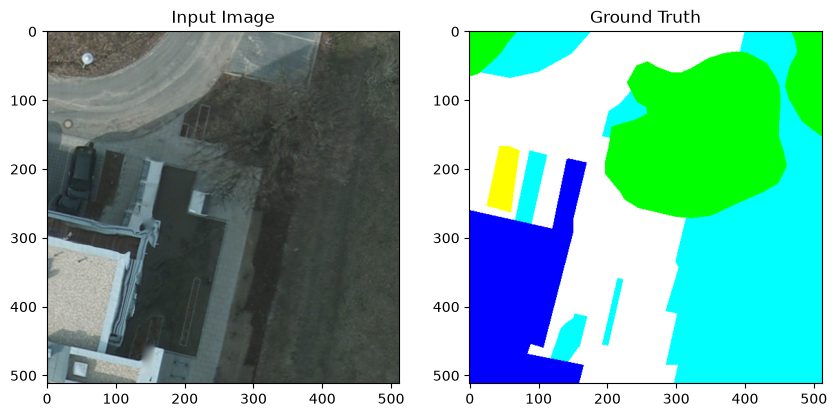

In [9]:
img, label = train_dataset.get_tif_by_id("2_12_512_1024")

plt.subplots(1, 2, figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Input Image')
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(label)
plt.title('Ground Truth')
plt.show()

# Training starts

In [10]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [11]:
print(torch.cuda.memory_allocated() / 1024**3)
print(torch.cuda.memory_reserved() / 1024**3)

0.0
0.0


In [12]:
print(torch.cuda.memory_summary())

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |      0 B   |
|       from small pool |      0 B   |      0 B   |      0 B   |      0 B   |
|---------------------------------------------------------------------------|
| Active memory         |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |

In [13]:
# OBS! 
# model is named "model"

model = Vanilla_UNet(img_dim=512, n_class=6, in_channels=3)

optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = DiceFocalLoss(w1=1, w2=1)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.4, patience=5, min_lr=1e-6)

num_epochs = 80


print(model.__class__.__name__)


# model, train_losses, train_accs, val_losses, val_accs
model, train_metrics, val_metrics = training_loop(
        model, optimizer, loss_fn, train_loader, val_loader, num_epochs, scheduler=scheduler, print_every=None)

Vanilla_UNet
Starting training


/home/edvard_edsgard/conda/envs/dml/lib/python3.11/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:84.)
  return F.conv2d(input, weight, bias, self.stride,


Epoch 1/80: 
Avg. Train loss: 2.641,  Train mean IoU: 0.200, Learning Rate: 0.00100, 
Avg. Val. loss: 1.932, Val. mean IoU: 0.277

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.4459
  -> Class 1 IoU: 0.4630
  -> Class 2 IoU: 0.4135
  -> Class 3 IoU: 0.0000
  -> Class 4 IoU: 0.3186
  -> Class 5 IoU: 0.0183

Epoch 2/80: 
Avg. Train loss: 1.667,  Train mean IoU: 0.332, Learning Rate: 0.00100, 
Avg. Val. loss: 1.664, Val. mean IoU: 0.359

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.5447
  -> Class 1 IoU: 0.4641
  -> Class 2 IoU: 0.3014
  -> Class 3 IoU: 0.2805
  -> Class 4 IoU: 0.4646
  -> Class 5 IoU: 0.0987

Epoch 3/80: 
Avg. Train loss: 1.522,  Train mean IoU: 0.381, Learning Rate: 0.00100, 
Avg. Val. loss: 1.596, Val. mean IoU: 0.389

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.5427
  -> Class 1 IoU: 0.5057
  -> Class 2 IoU: 0.3662
  -> Class 3 IoU: 0.2350
  -> Class 4 IoU: 0.5812
  -> Class 5 IoU: 0.1060

Epoch 4/80: 
Avg. Train loss: 1.427,  Train mean IoU: 0

In [ ]:
"""
Epoch 66/80: 
Avg. Train loss: 0.553,  Train mean IoU: 0.709, Learning Rate: 0.00006, 
Avg. Val. loss: 0.878, Val. mean IoU: 0.627

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.7154
  -> Class 1 IoU: 0.7342
  -> Class 2 IoU: 0.6395
  -> Class 3 IoU: 0.6541
  -> Class 4 IoU: 0.7831
  -> Class 5 IoU: 0.2348

Best model saved after epoch 66. 
"""

# Plots after training and validation metrics 


Length of train_losses: 9440, Length of val_losses: 80


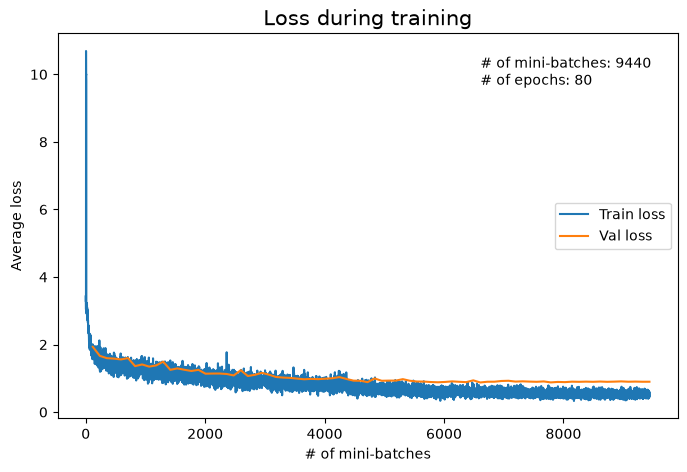

In [15]:
train_losses = train_metrics['loss'] 
val_losses = val_metrics['loss']

plot_train_val_losses(train_losses, val_losses, fig_size=(8,5), file_name="loss_during_training_run1")


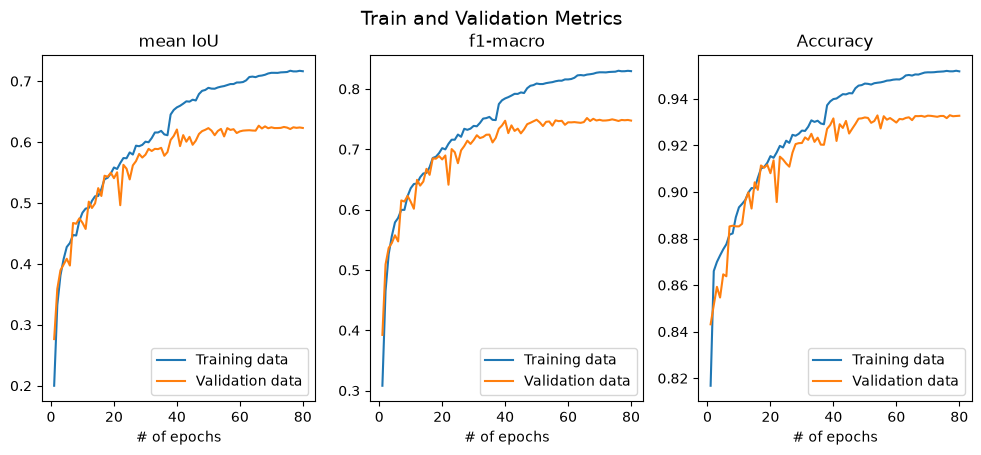

In [17]:
plot_train_val_metrics(train_metrics, val_metrics, fig_size=(12,4.5), file_name="metrics_training_run1")

# Displays of predictions
## best model after 66 epochs 

In [68]:
best_model = Vanilla_UNet(img_dim=512, n_class=6, in_channels=3)

best_model.load_state_dict(torch.load('Vanilla_UNet_best_model_epoch66.pth'))

#print(best_model)

<All keys matched successfully>

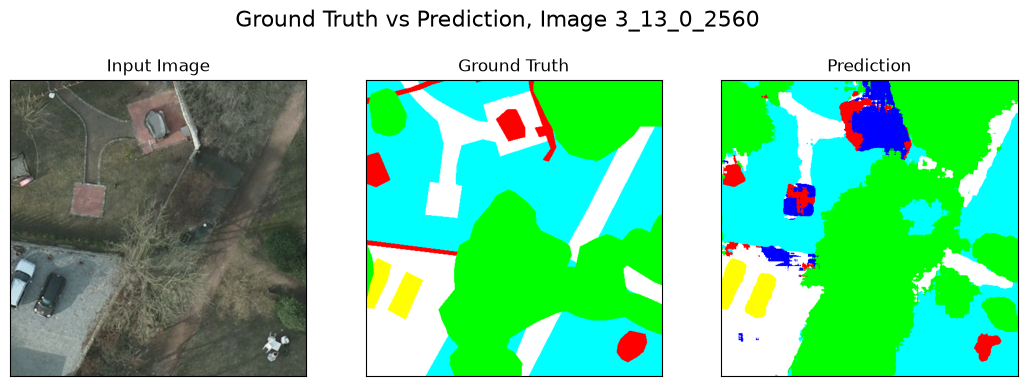

In [69]:
display_prediction(best_model, val_dataset, 25, fig_size=(13, 4.5), file_name=None)


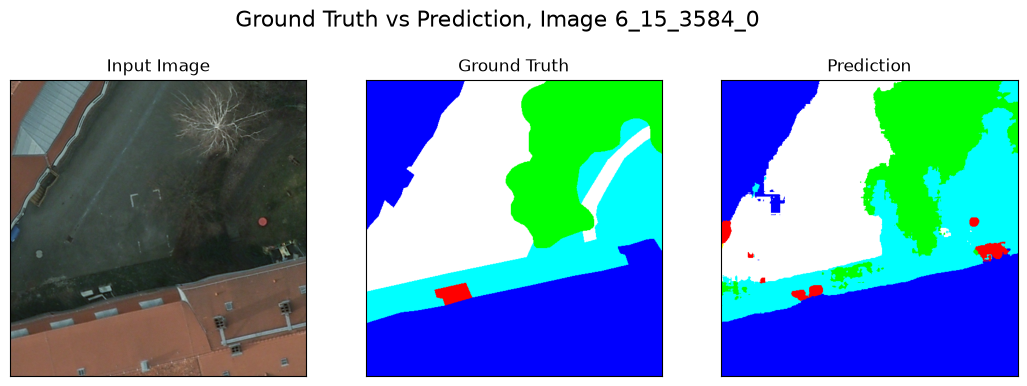

In [81]:
display_prediction(best_model, val_dataset, 550, fig_size=(13, 4.5), file_name="prediction_val550_run1")


# Test data performance

In [82]:
test_dataset = PotsdamDataset(root="./test_patches", transform=None)

test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

In [83]:
conf_matrix, test_miou, test_f1_macro, test_accuracy = test_score(best_model, loss_fn, test_loader)

RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!

In [85]:
def test_score(model, loss_fn, test_loader):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    conf_matrix = torch.zeros((6, 6), dtype=torch.int64)

    tp_, fp_, fn_, tn_ = [], [], [], []
    
    model.eval()
    with torch.no_grad():
        for batch_index, (x, y) in enumerate(test_loader, 1):
            inputs, labels = x.to(device), y.to(device)
            logits = model.forward(inputs)

            # No need for loss of test data
            #batch_loss = loss_fn(logits, labels)

            hard_preds = output_to_label(logits)

            # Calculate the mean intersection over union (mIoU) for this batch
            # Compute pixel statistics
            tp, fp, fn, tn = smp.metrics.get_stats(
                hard_preds, labels, mode="multiclass", num_classes=model.n_class)

            tp_.append(tp)
            fp_.append(fp)
            fn_.append(fn)
            tn_.append(tn)

            conf_matrix += confusion_matrix_6x6(hard_preds, labels).cpu()

            # end of batch loop



    # Compute the mean IoU for the entire epoch
    tp_total = torch.cat(tp_, dim=0)
    fp_total = torch.cat(fp_, dim=0)
    fn_total = torch.cat(fn_, dim=0)
    tn_total = torch.cat(tn_, dim=0)

    test_miou = smp.metrics.iou_score(tp_total, fp_total, fn_total, tn_total, reduction="macro").item()

    test_f1_macro = smp.metrics.f1_score(tp_total, fp_total, fn_total, tn_total, reduction="macro").item()

    test_accuracy = smp.metrics.accuracy(tp_total, fp_total, fn_total, tn_total, reduction="micro").item()

    
    print(f"Test mean IoU: {test_miou:.3f}")
    print(f"Test F1 Score (macro): {test_f1_macro:.3f}")
    print(f"Test Accuracy: {test_accuracy:.3f}")

    # Get per-class IoU values to see which specific class performace
    tp_sum = tp_total.sum(dim=0)
    fp_sum = fp_total.sum(dim=0)
    fn_sum = fn_total.sum(dim=0)
    per_class_iou = tp_sum / (tp_sum + fp_sum + fn_sum + 1e-7)

    print("\nPer-class IoU of Test set:")
    for class_idx, score in enumerate(per_class_iou):
        print(f"  -> Class {class_idx} IoU: {score.item():.4f}")
    print()


    return conf_matrix, test_miou, test_f1_macro, test_accuracy


In [92]:
conf_matrix, test_miou, test_f1_macro, test_accuracy = test_score(best_model, loss_fn, test_loader)

Test mean IoU: 0.615
Test F1 Score (macro): 0.739
Test Accuracy: 0.931

Per-class IoU of Test set:
  -> Class 0 IoU: 0.7135
  -> Class 1 IoU: 0.7351
  -> Class 2 IoU: 0.6341
  -> Class 3 IoU: 0.6093
  -> Class 4 IoU: 0.7929
  -> Class 5 IoU: 0.2021



In [93]:
conf_matrix_ = conf_matrix.cpu().numpy()
conf_matrix_

array([[80161640,  4560849,  5264341,  2730178,   234770,  2558563],
       [ 8097361, 59239978,  1617445,   942176,    64681,  2363463],
       [ 2101079,  1051555, 45959816,  5986744,     8428,   959818],
       [ 2140652,   442934,  6865219, 31982365,   106239,   524095],
       [  355010,    96088,    13804,    79654,  4918539,   221475],
       [ 4139456,  2113720,  2646822,   688657,   104456,  4132746]])

In [95]:
norm_conf_matrix_ = conf_matrix_.astype('float') / conf_matrix_.sum(axis=1)[:, np.newaxis]
norm_conf_matrix_


array([[8.39298019e-01, 4.77524104e-02, 5.51180212e-02, 2.85851560e-02,
        2.45805844e-03, 2.67883349e-02],
       [1.11957820e-01, 8.19079057e-01, 2.23635351e-02, 1.30269567e-02,
        8.94309118e-04, 3.26783215e-02],
       [3.74741383e-02, 1.87551813e-02, 8.19723818e-01, 1.06777552e-01,
        1.50318973e-04, 1.71189910e-02],
       [5.08933775e-02, 1.05306268e-02, 1.63218581e-01, 7.60371408e-01,
        2.52580126e-03, 1.24602059e-02],
       [6.24515135e-02, 1.69033014e-02, 2.42832791e-03, 1.40123176e-02,
        8.65243809e-01, 3.89607305e-02],
       [2.99399596e-01, 1.52881662e-01, 1.91439995e-01, 4.98093536e-02,
        7.55511937e-03, 2.98914273e-01]])

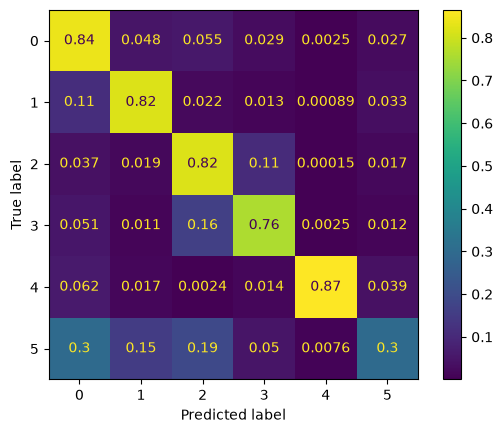

In [97]:
disp = ConfusionMatrixDisplay(confusion_matrix=norm_conf_matrix_,
                              display_labels=[0,1,2,3,4,5],
                             )

disp.plot()
plt.show()

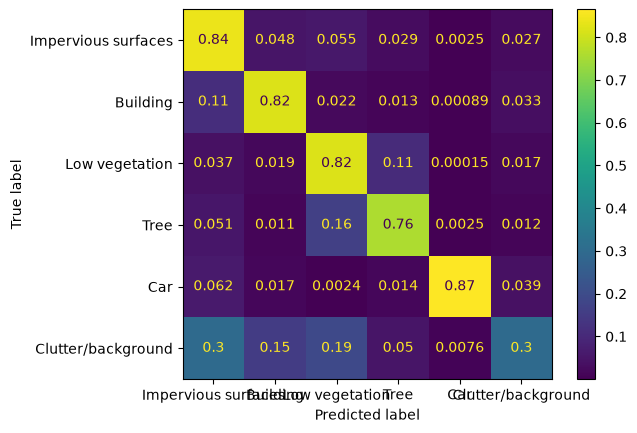

In [103]:
text_labels = ["Impervious surfaces", "Building",  "Low vegetation", "Tree", "Car", "Clutter/background"]

disp = ConfusionMatrixDisplay(confusion_matrix=norm_conf_matrix_,
                              display_labels=text_labels,
                             )

disp.plot()
plt.show()